# Proyecto Integrador de Ciencia de Datos
## Fase 1: Planteamiento del problema, descripción del conjunto de datos y análisis exploratorio (EDA)

**Universidad de La Salle**, Maestría en Inteligencia Artificial
**Asignatura:** Ciencia de Datos (2026-2). **Docente:** Fabián Camilo Castro Riveros
**Estudiante:** Martín Gracia Socha (trabajo individual)
**Entrega:** Entregable 1, domingo 1 de noviembre de 2026

**Conjunto de datos:** METABRIC, *Breast Cancer Gene Expression Profiles* (Kaggle)

### Contenido
1. Configuración del entorno
2. Planteamiento del problema y objetivos
3. Ficha técnica del conjunto de datos
4. Carga y estructura de los datos
5. Diccionario de datos
6. Diagnóstico de calidad de datos
7. Análisis univariado
8. Análisis bivariado y multivariado
9. Síntesis de hallazgos
10. Implicaciones para la Fase 2

## 1. Configuración del entorno

In [1]:
import sys
import warnings
from pathlib import Path

# --- Entorno: en Google Colab se clona el repositorio y se instalan dependencias faltantes ---
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/MartinGia/metabric-proyecto-integrador.git"
if IN_COLAB:
    # En Colab se clona el repositorio (datos, código y modelos) y se instalan las librerías que Colab no trae.
    import os, subprocess, importlib.util
    repo_dir = Path("/content/metabric-proyecto-integrador")
    if not (repo_dir / "src" / "config.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "notebooks")
    for pkg, module in [("imbalanced-learn", "imblearn"), ("xgboost", "xgboost"), ("shap", "shap")]:
        if importlib.util.find_spec(module) is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

def find_project_root():
    for c in [Path.cwd(), *Path.cwd().parents]:
        if (c / "src" / "config.py").exists():
            return c
    raise FileNotFoundError("No se encontró la carpeta del proyecto (debe contener src/config.py). "
                            "Abra el notebook desde la carpeta notebooks/ del repositorio.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# --- Localización de la raíz del proyecto (carpeta que contiene src/config.py) ---
# Funciona en Jupyter local, VS Code y Google Colab.
ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config
from src.eda_utils import (descriptive_table, frequency_table, missing_table,
                           outliers_iqr, outliers_zscore, chi2_tests)

config.ensure_dirs()
warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(config.RANDOM_STATE)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    plt.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

print("Carpeta del proyecto:", config.ROOT_DIR.name)
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

Carpeta del proyecto: repo
pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2


## 2. Planteamiento del problema y objetivos

### 2.1 Contextualización del dominio
El cáncer de mama es el cáncer más frecuente en mujeres a nivel mundial y una de sus principales causas de muerte por cáncer. Es, además, una enfermedad **molecularmente heterogénea**: tumores con el mismo estadio clínico pueden responder de forma distinta al tratamiento y tener pronósticos diferentes. Para capturar esa heterogeneidad, la oncología usa dos tipos de herramientas:

* **Índices clínico-patológicos**, como el *Nottingham Prognostic Index* (NPI), que combina el tamaño del tumor, el compromiso ganglionar y el grado histológico para estimar el riesgo de la paciente.
* **Clasificaciones moleculares**, como los subtipos intrínsecos **PAM50** (Luminal A, Luminal B, HER2-enriquecido, Basal, Normal-like y Claudin-low), definidos a partir de la expresión de genes y asociados a terapias específicas.

El consorcio **METABRIC** (*Molecular Taxonomy of Breast Cancer International Consortium*, Canadá y Reino Unido) reunió datos clínicos y genómicos de cerca de 2.000 tumores primarios. Este proyecto usa la versión de Kaggle, que integra 31 atributos clínicos, z-scores de expresión de ARNm de 489 genes y el estado mutacional de 173 genes para 1.904 pacientes.

**Impacto potencial.** Un modelo que estime el riesgo pronóstico y el subtipo molecular a partir de un panel reducido de genes, junto con una segmentación no supervisada de pacientes, puede apoyar la estratificación del riesgo, priorizar pruebas moleculares y orientar la discusión de alternativas terapéuticas. El proyecto es un ejercicio académico y no pretende reemplazar el criterio clínico.

### 2.2 Preguntas de investigación
**Pregunta principal.** ¿En qué medida el perfil clínico y la expresión génica del tumor primario permiten estimar el riesgo pronóstico de una paciente con cáncer de mama, predecir su subtipo molecular intrínseco e identificar grupos de pacientes con perfiles biológicos diferenciados?

**Preguntas secundarias.**
1. **(Regresión)** ¿Qué tan bien puede estimarse el *Nottingham Prognostic Index* a partir de la expresión génica y de variables clínicas que no forman parte de su fórmula, y qué genes aportan más a esa estimación?
2. **(Clasificación)** ¿Con qué desempeño (F1 macro y AUC-ROC) puede predecirse el subtipo PAM50 + Claudin-low usando el panel de 489 genes disponible y las variables clínicas?
3. **(Clustering)** ¿Los grupos que emergen de forma no supervisada en el espacio de expresión génica coinciden con los subtipos PAM50 conocidos y presentan diferencias en el NPI y en la supervivencia?

### 2.3 Objetivos (formato SMART)
**Objetivo general.** Desarrollar, a más tardar el 28 de noviembre de 2026, una solución analítica reproducible sobre los 1.904 registros de METABRIC que integre un modelo de regresión del NPI, un modelo de clasificación del subtipo PAM50 y una segmentación no supervisada de pacientes, y que se comunique mediante un dashboard interactivo desplegado en línea.

**Objetivos específicos.**
1. **Regresión.** Entrenar y comparar, antes del 22 de noviembre de 2026, un modelo lineal regularizado (Lasso, Ridge o ElasticNet) y un modelo de ensamble (Random Forest o Gradient Boosting) que estimen el NPI sin usar sus componentes (tamaño tumoral, ganglios positivos y grado histológico), con la meta de reducir el RMSE frente al modelo base y alcanzar un R² de al menos 0,20 en el conjunto de prueba.
2. **Clasificación.** Entrenar y comparar, antes del 22 de noviembre de 2026, dos algoritmos de clasificación (por ejemplo, SVM y Random Forest) para el subtipo PAM50 + Claudin-low con partición estratificada, con la meta de alcanzar un F1 macro de al menos 0,75 en el conjunto de prueba, superar al modelo base en validación cruzada (F1 macro = 0,698) y reducir la brecha de sobreajuste entre entrenamiento y validación cruzada por debajo de 0,15 (el modelo base tiene 0,30).
3. **Clustering.** Segmentar a las pacientes con K-Means (eligiendo K con el método del codo y el coeficiente de silueta) y con un segundo algoritmo (Clustering Jerárquico Aglomerativo o DBSCAN) sobre la expresión génica reducida por PCA, y caracterizar cada clúster por su perfil clínico, su correspondencia con PAM50 (Índice de Rand Ajustado) y su NPI promedio, antes del 22 de noviembre de 2026.

> La meta de regresión (R² ≥ 0,20) es moderada porque, como muestra el EDA, ningún gen supera una correlación de 0,40 con el NPI una vez se excluyen sus componentes. La meta de clasificación (F1 macro ≥ 0,75) se fijó por encima de una regresión logística de referencia, que obtiene F1 macro = 0,698 en validación cruzada sobre entrenamiento (cuaderno 03); el conjunto de prueba no se usó para definirla.

## 3. Ficha técnica del conjunto de datos

| Campo | Detalle |
|---|---|
| **Nombre** | Breast Cancer Gene Expression Profiles (METABRIC) |
| **Repositorio de origen** | Kaggle Datasets (repositorio permitido por la guía) |
| **Autor de la publicación en Kaggle** | Raghad Alharbi |
| **URL exacta de acceso** | https://www.kaggle.com/datasets/raghadalharbi/breast-cancer-gene-expression-profiles-metabric |
| **Fuente primaria** | cBioPortal for Cancer Genomics, estudio *Breast Cancer (METABRIC, Nature 2012 & Nat Commun 2016)* (`brca_metabric`) |
| **Archivo** | `METABRIC_RNA_Mutation.csv` (8,4 MB) |
| **Fecha de extracción** | 24 de octubre de 2026 |
| **Licencia** | Base de datos: *Open Database License* (ODbL); contenidos: *Database Contents License* (DbCL) v1.0. Ambas son licencias abiertas de Open Data Commons |
| **Dimensiones** | 1.904 registros (pacientes) × 693 variables |
| **Unidad de observación** | Una paciente con cáncer de mama primario |
| **Bloques de variables** | 31 clínicas, 489 de expresión génica (z-scores de ARNm) y 173 de mutaciones |
| **Referencias** | Curtis et al. (2012), *Nature* 486:346-352; Pereira et al. (2016), *Nature Communications* 7:11479 |

La evidencia de la licencia (capturas de la página de Kaggle y del texto de la licencia DbCL) está en `docs/evidencias/`.

## 4. Carga y estructura de los datos

In [2]:
df = pd.read_csv(config.RAW_FILE, low_memory=False)
clinical_cols, gene_cols, mut_cols = config.split_blocks(df)

print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]:,} columnas")
print(f"Variables clínicas: {len(clinical_cols)} | Expresión génica: {len(gene_cols)} | Mutaciones: {len(mut_cols)}")
df[clinical_cols].head()

Dimensiones: 1,904 filas × 693 columnas
Variables clínicas: 31 | Expresión génica: 489 | Mutaciones: 173


,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,er_status,neoplasm_histologic_grade,her2_status_measured_by_snp6,her2_status,tumor_other_histologic_subtype,hormone_therapy,inferred_menopausal_state,integrative_cluster,primary_tumor_laterality,lymph_nodes_examined_positive,mutation_count,nottingham_prognostic_index,oncotree_code,overall_survival_months,overall_survival,pr_status,radio_therapy,3-gene_classifier_subtype,tumor_size,tumor_stage,death_from_cancer
0,0,75.650,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,claudin-low,1.000,Positve,Positive,3.000,NEUTRAL,Negative,Ductal/NST,1,Post,4ER+,Right,10.000,NaN,6.044,IDC,140.500,1,Negative,1,ER-/HER2-,22.000,2.000,Living
1,2,43.190,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,LumA,1.000,Positve,Positive,3.000,NEUTRAL,Negative,Ductal/NST,1,Pre,4ER+,Right,0.000,2.000,4.020,IDC,84.633,1,Positive,1,ER+/HER2- High Prolif,10.000,1.000,Living
2,5,48.870,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,LumB,1.000,Positve,Positive,2.000,NEUTRAL,Negative,Ductal/NST,1,Pre,3,Right,1.000,2.000,4.030,IDC,163.700,0,Positive,0,NaN,15.000,2.000,Died of Disease
3,6,47.680,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,LumB,1.000,Positve,Positive,2.000,NEUTRAL,Negative,Mixed,1,Pre,9,Right,3.000,1.000,4.050,MDLC,164.933,1,Positive,1,NaN,25.000,2.000,Living
4,8,76.970,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,LumB,1.000,Positve,Positive,3.000,NEUTRAL,Negative,Mixed,1,Post,9,Right,8.000,2.000,6.080,MDLC,41.367,0,Positive,1,ER+/HER2- High Prolif,40.000,2.000,Died of Disease


In [3]:
# Verificación de los requisitos obligatorios de la guía (sección 2.2)
num_clin = df[clinical_cols].select_dtypes("number").columns
cat_clin = df[clinical_cols].columns.difference(num_clin)
checks = pd.DataFrame({
    "requisito": ["Mínimo 600 registros", "Mínimo 5 variables",
                  "Incluye variables cuantitativas", "Incluye variables cualitativas",
                  "Variable continua para regresión (NPI)",
                  "Variable categórica para clasificación (PAM50)",
                  "Varias cuantitativas para clustering (genes)"],
    "valor": [len(df), df.shape[1], len(num_clin) + len(gene_cols), len(cat_clin) + len(mut_cols),
              df[config.TARGET_REGRESSION].nunique(), df[config.TARGET_CLASSIFICATION].nunique(),
              len(gene_cols)],
})
checks["cumple"] = [len(df) >= 600, df.shape[1] >= 5, True, True,
                    pd.api.types.is_float_dtype(df[config.TARGET_REGRESSION]),
                    df[config.TARGET_CLASSIFICATION].nunique() >= 2, len(gene_cols) >= 2]
checks

,requisito,valor,cumple
0,Mínimo 600 registros,1904,True
1,Mínimo 5 variables,693,True
2,Incluye variables cuantitativas,503,True
3,Incluye variables cualitativas,190,True
4,Variable continua para regresión (NPI),310,True
5,Variable categórica para clasificación (PAM50),7,True
6,Varias cuantitativas para clustering (genes),489,True


In [4]:
# Tipos de dato en memoria por bloque
pd.DataFrame({
    "clínicas": df[clinical_cols].dtypes.astype(str).value_counts(),
    "genes": df[gene_cols].dtypes.astype(str).value_counts(),
    "mutaciones": df[mut_cols].dtypes.astype(str).value_counts(),
}).fillna(0).astype(int)

,clínicas,genes,mutaciones
float64,9,489,0
int64,5,0,0
str,17,0,173


## 5. Diccionario de datos
El diccionario detalla las 31 variables clínicas. Los bloques de expresión génica (489 columnas) y de mutaciones (173 columnas) son homogéneos y se describen como grupo. El diccionario completo de las 693 columnas se exporta a `docs/diccionario_datos.csv`.

In [5]:
# (tipo de variable, descripción funcional)
CLIN_DICT = {
    "patient_id": ("Identificador", "Identificador anónimo de la paciente; no se usa como predictor."),
    "age_at_diagnosis": ("Cuantitativa continua", "Edad de la paciente al diagnóstico (años)."),
    "type_of_breast_surgery": ("Cualitativa nominal", "Tipo de cirugía: mastectomía o cirugía conservadora de mama."),
    "cancer_type": ("Cualitativa nominal", "Tipo de cáncer: carcinoma de mama o sarcoma de mama."),
    "cancer_type_detailed": ("Cualitativa nominal", "Tipo histológico detallado (ductal, lobulillar, mixto, etc.)."),
    "cellularity": ("Cualitativa ordinal", "Celularidad tumoral tras quimioterapia: Low < Moderate < High."),
    "chemotherapy": ("Cualitativa nominal (binaria)", "Recibió quimioterapia (1 = sí, 0 = no)."),
    "pam50_+_claudin-low_subtype": ("Cualitativa nominal", "Subtipo intrínseco PAM50 + Claudin-low. VARIABLE OBJETIVO DE CLASIFICACIÓN."),
    "cohort": ("Cualitativa nominal", "Cohorte de reclutamiento (1 a 5), codificada con números."),
    "er_status_measured_by_ihc": ("Cualitativa nominal (binaria)", "Receptor de estrógeno medido por inmunohistoquímica."),
    "er_status": ("Cualitativa nominal (binaria)", "Estado del receptor de estrógeno (positivo o negativo)."),
    "neoplasm_histologic_grade": ("Cualitativa ordinal", "Grado histológico de Nottingham (1 = bien diferenciado, 3 = poco diferenciado). Componente del NPI."),
    "her2_status_measured_by_snp6": ("Cualitativa nominal", "Número de copias de HER2 medido con arreglos SNP6 (LOSS, NEUTRAL, GAIN, UNDEF)."),
    "her2_status": ("Cualitativa nominal (binaria)", "Estado del receptor HER2 (positivo o negativo)."),
    "tumor_other_histologic_subtype": ("Cualitativa nominal", "Subtipo histológico (Ductal/NST, Lobular, Mixed, Medullary, etc.)."),
    "hormone_therapy": ("Cualitativa nominal (binaria)", "Recibió terapia hormonal (1 = sí, 0 = no)."),
    "inferred_menopausal_state": ("Cualitativa nominal (binaria)", "Estado menopáusico inferido: Pre o Post."),
    "integrative_cluster": ("Cualitativa nominal", "Clúster integrativo METABRIC (IntClust 1 a 10, con 4ER+ y 4ER-)."),
    "primary_tumor_laterality": ("Cualitativa nominal (binaria)", "Lateralidad del tumor primario: Left o Right."),
    "lymph_nodes_examined_positive": ("Cuantitativa discreta", "Número de ganglios linfáticos positivos. Componente del NPI."),
    "mutation_count": ("Cuantitativa discreta", "Número de genes con mutación detectada en el tumor."),
    "nottingham_prognostic_index": ("Cuantitativa continua", "Nottingham Prognostic Index; a mayor valor, peor pronóstico. VARIABLE OBJETIVO DE REGRESIÓN."),
    "oncotree_code": ("Cualitativa nominal", "Código OncoTree del tipo tumoral (IDC, ILC, MDLC, etc.)."),
    "overall_survival_months": ("Cuantitativa continua", "Meses desde la intervención hasta la muerte o el último seguimiento (dato censurado)."),
    "overall_survival": ("Cualitativa nominal (binaria)", "Estado vital al cierre del seguimiento (1 = viva, 0 = fallecida)."),
    "pr_status": ("Cualitativa nominal (binaria)", "Estado del receptor de progesterona (positivo o negativo)."),
    "radio_therapy": ("Cualitativa nominal (binaria)", "Recibió radioterapia (1 = sí, 0 = no)."),
    "3-gene_classifier_subtype": ("Cualitativa nominal", "Subtipo según el clasificador de 3 genes (ER/HER2 y proliferación)."),
    "tumor_size": ("Cuantitativa continua", "Tamaño del tumor (mm). Componente del NPI."),
    "tumor_stage": ("Cualitativa ordinal", "Estadio del tumor (0 a 4)."),
    "death_from_cancer": ("Cualitativa nominal", "Causa de muerte: Living, Died of Disease o Died of Other Causes."),
}

def allowed_values(s, kind):
    s = s.dropna()
    if kind.startswith("Cuantitativa"):
        return f"[{s.min():g}, {s.max():g}]"
    if kind == "Identificador":
        return f"{s.nunique()} valores únicos"
    vals = sorted(map(str, s.unique()))
    return ", ".join(vals) if len(vals) <= 12 else f"{len(vals)} categorías"

dict_rows = []
for c in clinical_cols:
    kind, desc = CLIN_DICT[c]
    dict_rows.append({"variable": c, "bloque": "Clínico", "tipo": kind, "dtype": str(df[c].dtype),
                      "descripcion": desc, "rango_valores": allowed_values(df[c], kind),
                      "faltantes_%": round(100 * df[c].isna().mean(), 2)})
for c in gene_cols:
    dict_rows.append({"variable": c, "bloque": "Expresión génica", "tipo": "Cuantitativa continua",
                      "dtype": str(df[c].dtype),
                      "descripcion": f"Z-score de expresión de ARNm del gen {c.upper()}.",
                      "rango_valores": f"[{df[c].min():.2f}, {df[c].max():.2f}]",
                      "faltantes_%": round(100 * df[c].isna().mean(), 2)})
for c in mut_cols:
    dict_rows.append({"variable": c, "bloque": "Mutación", "tipo": "Cualitativa nominal",
                      "dtype": str(df[c].dtype),
                      "descripcion": f"Mutación en {c[:-4].upper()}: '0' = sin mutación; otro valor = cambio de proteína (p. ej., R175H).",
                      "rango_valores": f"{df[c].nunique()} valores distintos",
                      "faltantes_%": round(100 * df[c].isna().mean(), 2)})

data_dict = pd.DataFrame(dict_rows)
data_dict.to_csv(config.DOCS_DIR / "diccionario_datos.csv", index=False, encoding="utf-8-sig")
print(f"Diccionario completo exportado: {len(data_dict)} variables")

with pd.option_context("display.max_colwidth", 90, "display.max_rows", 40):
    display(data_dict[data_dict.bloque == "Clínico"].drop(columns="bloque").set_index("variable"))

Diccionario completo exportado: 693 variables


,tipo,dtype,descripcion,rango_valores,faltantes_%
variable,,,,,
patient_id,Identificador,int64,Identificador anónimo de la paciente; no se usa como predictor.,1904 valores únicos,0.000
age_at_diagnosis,Cuantitativa continua,float64,Edad de la paciente al diagnóstico (años).,"[21.93, 96.29]",0.000
type_of_breast_surgery,Cualitativa nominal,str,Tipo de cirugía: mastectomía o cirugía conservadora de mama.,"BREAST CONSERVING, MASTECTOMY",1.160
cancer_type,Cualitativa nominal,str,Tipo de cáncer: carcinoma de mama o sarcoma de mama.,"Breast Cancer, Breast Sarcoma",0.000
cancer_type_detailed,Cualitativa nominal,str,"Tipo histológico detallado (ductal, lobulillar, mixto, etc.).","Breast, Breast Invasive Ductal Carcinoma, Breast Invasive Lobular Carcinoma, Breast In...",0.790
cellularity,Cualitativa ordinal,str,Celularidad tumoral tras quimioterapia: Low < Moderate < High.,"High, Low, Moderate",2.840
chemotherapy,Cualitativa nominal (binaria),int64,"Recibió quimioterapia (1 = sí, 0 = no).","0, 1",0.000
pam50_+_claudin-low_subtype,Cualitativa nominal,str,Subtipo intrínseco PAM50 + Claudin-low. VARIABLE OBJETIVO DE CLASIFICACIÓN.,"Basal, Her2, LumA, LumB, NC, Normal, claudin-low",0.000
cohort,Cualitativa nominal,float64,"Cohorte de reclutamiento (1 a 5), codificada con números.","1.0, 2.0, 3.0, 4.0, 5.0",0.000


In [6]:
# Resumen de los bloques homogéneos
gene_stats = df[gene_cols].describe().T
mut_rate = (df[mut_cols].astype(str) != "0").mean()
pd.DataFrame({
    "bloque": ["Expresión génica (z-scores de ARNm)", "Mutaciones"],
    "n_variables": [len(gene_cols), len(mut_cols)],
    "tipo": ["Cuantitativa continua", "Cualitativa nominal (texto: '0' o código de la mutación)"],
    "resumen": [f"media ≈ {gene_stats['mean'].mean():.2f}, desv. est. ≈ {gene_stats['std'].mean():.2f}; "
                f"rango global [{gene_stats['min'].min():.2f}, {gene_stats['max'].max():.2f}]",
                f"% de pacientes mutadas por gen: mediana {100*mut_rate.median():.1f} %, "
                f"máximo {100*mut_rate.max():.1f} % ({mut_rate.idxmax()})"],
}).set_index("bloque")

,n_variables,tipo,resumen
bloque,,,
Expresión génica (z-scores de ARNm),489,Cuantitativa continua,"media ≈ -0.00, desv. est. ≈ 1.00; rango global..."
Mutaciones,173,Cualitativa nominal (texto: '0' o código de la...,"% de pacientes mutadas por gen: mediana 1.6 %,..."


## 6. Diagnóstico de calidad de datos
### 6.1 Datos faltantes (porcentaje exacto por variable)

In [7]:
miss = missing_table(df)
miss_clin = miss.loc[clinical_cols].query("faltantes > 0").sort_values("porcentaje", ascending=False)
print(f"Celdas faltantes en todo el conjunto: {df.isna().sum().sum():,} de {df.size:,} "
      f"({100 * df.isna().sum().sum() / df.size:.3f} %)")
print(f"Variables con faltantes: clínicas {(miss.loc[clinical_cols, 'faltantes'] > 0).sum()}, "
      f"genes {(miss.loc[gene_cols, 'faltantes'] > 0).sum()}, mutaciones {(miss.loc[mut_cols, 'faltantes'] > 0).sum()}")
print(f"Filas completas en las variables clínicas: {df[clinical_cols].dropna().shape[0]:,} "
      f"({100 * df[clinical_cols].dropna().shape[0] / len(df):.1f} %)")
miss_clin

Celdas faltantes en todo el conjunto: 1,100 de 1,319,472 (0.083 %)
Variables con faltantes: clínicas 13, genes 0, mutaciones 0
Filas completas en las variables clínicas: 1,092 (57.4 %)


,faltantes,porcentaje
tumor_stage,501,26.313
3-gene_classifier_subtype,204,10.714
primary_tumor_laterality,106,5.567
neoplasm_histologic_grade,72,3.782
cellularity,54,2.836
mutation_count,45,2.363
er_status_measured_by_ihc,30,1.576
type_of_breast_surgery,22,1.155
tumor_size,20,1.050
cancer_type_detailed,15,0.788


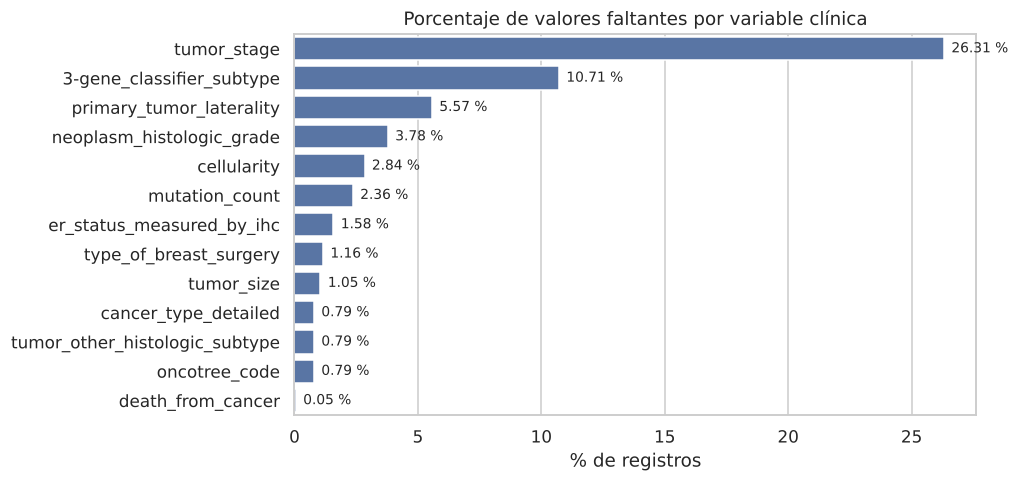

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=miss_clin["porcentaje"], y=miss_clin.index, color="#4C72B0", ax=ax)
for i, v in enumerate(miss_clin["porcentaje"]):
    ax.text(v + 0.3, i, f"{v:.2f} %", va="center", fontsize=9)
ax.set(title="Porcentaje de valores faltantes por variable clínica", xlabel="% de registros", ylabel="")
savefig("01_faltantes")
plt.show()

In [9]:
# ¿Los faltantes se concentran en algún subgrupo? Primer indicio del mecanismo (MCAR/MAR/MNAR)
stage_na = df["tumor_stage"].isna()
print("Proporción de tumor_stage faltante por cohorte:")
display((100 * stage_na.groupby(df["cohort"]).mean()).round(1).rename("% faltante").to_frame().T)
ct = pd.crosstab(df["cohort"], stage_na)
chi2, p, _, _ = stats.chi2_contingency(ct)
print(f"Chi² de independencia (faltante de tumor_stage vs. cohorte): chi2 = {chi2:.1f}, p = {p:.2e}")

Proporción de tumor_stage faltante por cohorte:


cohort,1.000,2.000,3.000,4.000,5.000
% faltante,4.000,0.000,14.300,100.000,84.400


Chi² de independencia (faltante de tumor_stage vs. cohorte): chi2 = 1232.6, p = 1.37e-265


### 6.2 Registros duplicados

In [10]:
print("Filas completamente duplicadas:", df.duplicated().sum())
print("patient_id duplicados:", df["patient_id"].duplicated().sum())
print("Filas duplicadas si se ignora patient_id:", df.drop(columns="patient_id").duplicated().sum())

Filas completamente duplicadas: 0
patient_id duplicados: 0


Filas duplicadas si se ignora patient_id: 0


### 6.3 Incoherencias y problemas de consistencia
Se verifican reglas de negocio y de consistencia entre variables relacionadas.

In [11]:
issues = []
def add(issue, n, detail):
    issues.append({"hallazgo": issue, "registros": int(n), "detalle": detail})

add("Error tipográfico en categoría", (df["er_status_measured_by_ihc"] == "Positve").sum(),
    "er_status_measured_by_ihc usa 'Positve' en lugar de 'Positive'.")
both = df[["er_status", "er_status_measured_by_ihc"]].dropna()
disc = (both["er_status"].str[:3] != both["er_status_measured_by_ihc"].str[:3]).sum()
add("Discrepancia entre medidas de ER", disc,
    "er_status no coincide con er_status_measured_by_ihc (métodos de medición distintos).")
inc = ((df["overall_survival"] == 1) & (df["death_from_cancer"] != "Living")).sum() + \
      ((df["overall_survival"] == 0) & (df["death_from_cancer"] == "Living")).sum()
add("Coherencia estado vital vs. causa de muerte", inc,
    "overall_survival (1 = viva) es coherente con death_from_cancer en todos los registros.")
add("Categoría 'NC' (no clasificado) en PAM50", (df[config.TARGET_CLASSIFICATION] == "NC").sum(),
    "Se excluirán del problema de clasificación.")
add("Clase de un solo registro", (df["cancer_type"] == "Breast Sarcoma").sum(),
    "cancer_type = 'Breast Sarcoma': un sarcoma no es un carcinoma; candidato a excluir.")
add("Categoría genérica", (df["cancer_type_detailed"] == "Breast").sum(),
    "cancer_type_detailed = 'Breast' no especifica el tipo histológico.")
add("Valor indeterminado", (df["her2_status_measured_by_snp6"] == "UNDEF").sum(),
    "her2_status_measured_by_snp6 = 'UNDEF'.")
add("Tumor en estadio 0", (df["tumor_stage"] == 0).sum(),
    "Estadio 0 (in situ) en una cohorte de tumores invasivos.")
add("Supervivencia de 0 meses", (df["overall_survival_months"] == 0).sum(),
    "overall_survival_months = 0.")
redund = pd.crosstab(df["cancer_type_detailed"], df["oncotree_code"]).gt(0).sum(axis=1).eq(1).all()
add("Variables redundantes", 0,
    f"oncotree_code y cancer_type_detailed codifican la misma información (mapeo uno a uno: {redund}).")

# Verificación de la fórmula del NPI con los datos
ln = df["lymph_nodes_examined_positive"]
node_stage = np.select([ln == 0, ln <= 3], [1, 2], 3)
npi_rebuilt = 0.002 * df["tumor_size"] + node_stage + df["neoplasm_histologic_grade"]
ok = (df["nottingham_prognostic_index"] - npi_rebuilt).abs() < 0.011
n_valid = npi_rebuilt.notna().sum()
add("NPI determinado por sus componentes", ok.sum(),
    f"En {ok.sum()} de {n_valid} registros con datos completos, NPI = grado + estadio ganglionar + 0,002 × tamaño (mm). "
    "La fórmula clínica usa 0,2 × tamaño en cm (0,02 × mm), así que el término de tamaño está reescalado en la fuente.")

with pd.option_context("display.max_colwidth", 130):
    display(pd.DataFrame(issues).set_index("hallazgo"))

,registros,detalle
hallazgo,,
Error tipográfico en categoría,1445,er_status_measured_by_ihc usa 'Positve' en lugar de 'Positive'.
Discrepancia entre medidas de ER,118,er_status no coincide con er_status_measured_by_ihc (métodos de medición distintos).
Coherencia estado vital vs. causa de muerte,0,overall_survival (1 = viva) es coherente con death_from_cancer en todos los registros.
Categoría 'NC' (no clasificado) en PAM50,6,Se excluirán del problema de clasificación.
Clase de un solo registro,1,cancer_type = 'Breast Sarcoma': un sarcoma no es un carcinoma; candidato a excluir.
Categoría genérica,17,cancer_type_detailed = 'Breast' no especifica el tipo histológico.
Valor indeterminado,4,her2_status_measured_by_snp6 = 'UNDEF'.
Tumor en estadio 0,4,Estadio 0 (in situ) en una cohorte de tumores invasivos.
Supervivencia de 0 meses,1,overall_survival_months = 0.


### 6.4 Valores atípicos (regla IQR y Z-score)
Se aplica la regla de Tukey (1,5 × IQR) y el criterio |z| > 3 a las variables clínicas cuantitativas.

In [12]:
quant_clin = ["age_at_diagnosis", "tumor_size", "lymph_nodes_examined_positive",
              "mutation_count", "nottingham_prognostic_index", "overall_survival_months"]
out_tbl = outliers_iqr(df, quant_clin).join(outliers_zscore(df, quant_clin))
out_tbl

,lim_inferior,lim_superior,atipicos_IQR,porcentaje_IQR,atipicos_Z,porcentaje_Z
variable,,,,,,
age_at_diagnosis,22.549,99.419,1,0.050,1,0.050
tumor_size,-2.500,49.500,142,7.540,28,1.490
lymph_nodes_examined_positive,-3.000,5.000,210,11.030,50,2.630
mutation_count,-3.000,13.000,62,3.340,22,1.180
nottingham_prognostic_index,0.055,8.032,0,0.000,0,0.000
overall_survival_months,-125.013,370.554,0,0.000,1,0.050


In [13]:
# Expresión génica: ya está estandarizada (z-score), así que se resume la proporción de valores extremos
z_abs = df[gene_cols].abs()
pct_extreme = 100 * (z_abs > 3).sum() / df[gene_cols].notna().sum()
print(f"Valores con |z| > 3 en el bloque génico: {100 * (z_abs > 3).to_numpy().sum() / df[gene_cols].notna().to_numpy().sum():.2f} % "
      f"(bajo normalidad se esperaría cerca de 0,27 %)")
print("Genes con mayor proporción de valores extremos:")
pct_extreme.sort_values(ascending=False).head(10).round(2).rename("% |z|>3").to_frame().T

Valores con |z| > 3 en el bloque génico: 0.93 % (bajo normalidad se esperaría cerca de 0,27 %)
Genes con mayor proporción de valores extremos:


,ttyh1,cdkn2a,gldc,mmp12,mmp24,col22a1,frmd3,map2,ugt2b15,dlec1
% |z|>3,3.470,3.200,3.100,2.840,2.630,2.570,2.570,2.570,2.520,2.420


## 7. Análisis univariado
### 7.1 Variables cuantitativas: tendencia central, dispersión, asimetría y curtosis

In [14]:
desc = descriptive_table(df, quant_clin)
desc

,n,media,mediana,moda,desv_est,varianza,coef_var_%,min,Q1,Q3,max,IQR,asimetria,curtosis_exceso
variable,,,,,,,,,,,,,,
age_at_diagnosis,1904,61.087,61.770,49.610,12.979,168.447,21.246,21.930,51.375,70.593,96.290,19.218,-0.192,-0.546
tumor_size,1884,26.239,23.000,20.000,15.161,229.855,57.781,1.000,17.000,30.000,182.000,13.000,3.275,20.916
lymph_nodes_examined_positive,1904,2.002,0.000,0.000,4.080,16.646,203.786,0.000,0.000,2.000,45.000,2.000,3.839,20.730
mutation_count,1859,5.698,5.000,5.000,4.059,16.474,71.236,1.000,3.000,7.000,80.000,4.000,5.183,70.132
nottingham_prognostic_index,1904,4.033,4.042,4.040,1.144,1.310,28.378,1.000,3.046,5.040,6.360,1.994,-0.071,-0.335
overall_survival_months,1904,125.121,115.617,192.200,76.334,"5,826.902",61.008,0.000,60.825,184.717,355.200,123.892,0.384,-0.782


In [15]:
# Prueba de normalidad de D'Agostino-Pearson (n grande)
norm = pd.DataFrame({c: stats.normaltest(df[c].dropna()) for c in quant_clin}, index=["estadístico K²", "p_valor"]).T
norm["¿normal? (α = 0,05)"] = np.where(norm["p_valor"] > 0.05, "Sí", "No")
norm

,estadístico K²,p_valor,"¿normal? (α = 0,05)"
age_at_diagnosis,57.662,0.000,No
tumor_size,"1,416.870",0.000,No
lymph_nodes_examined_positive,"1,574.629",0.000,No
mutation_count,"2,056.782",0.000,No
nottingham_prognostic_index,14.322,0.001,No
overall_survival_months,190.031,0.000,No


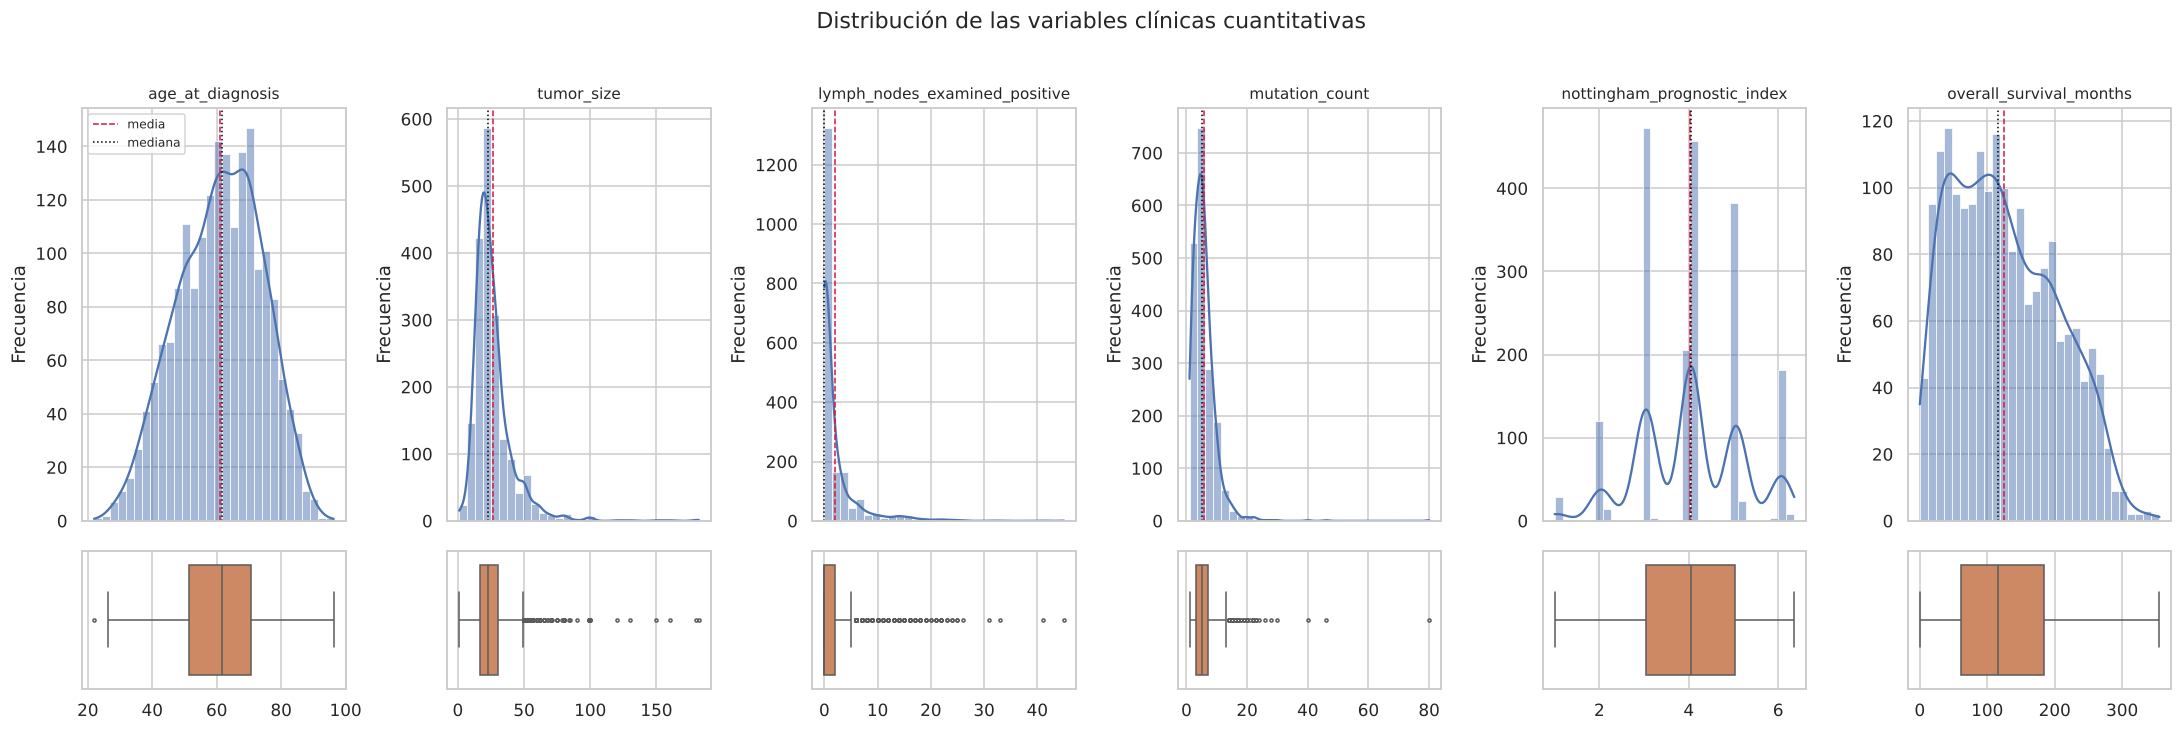

In [16]:
fig, axes = plt.subplots(2, len(quant_clin), figsize=(20, 6.5),
                         gridspec_kw={"height_ratios": [3, 1]}, sharex="col")
for i, c in enumerate(quant_clin):
    sns.histplot(df[c].dropna(), kde=True, ax=axes[0, i], color="#4C72B0", bins=30)
    axes[0, i].axvline(df[c].mean(), color="crimson", ls="--", lw=1, label="media")
    axes[0, i].axvline(df[c].median(), color="black", ls=":", lw=1, label="mediana")
    axes[0, i].set_title(c, fontsize=10)
    axes[0, i].set_xlabel("")
    axes[0, i].set_ylabel("Frecuencia")
    sns.boxplot(x=df[c], ax=axes[1, i], color="#DD8452", fliersize=2)
    axes[1, i].set_xlabel("")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Distribución de las variables clínicas cuantitativas", y=1.02)
plt.tight_layout()
savefig("02_univariado_cuantitativas")
plt.show()

In [17]:
# Valores distintos del NPI: la variable objetivo de regresión se concentra cerca de valores enteros
npi = df["nottingham_prognostic_index"]
print(f"Valores únicos del NPI: {npi.nunique()}")
print("Distribución del NPI redondeado a entero (%):")
(100 * npi.round().value_counts(normalize=True).sort_index()).round(2).rename("%").to_frame().T

Valores únicos del NPI: 310
Distribución del NPI redondeado a entero (%):


nottingham_prognostic_index,1.000,2.000,3.000,4.000,5.000,6.000
%,1.520,7.040,25.050,34.770,21.430,10.190


### 7.2 Variables cualitativas: tablas de frecuencias

In [18]:
cat_vars = ["pam50_+_claudin-low_subtype", "death_from_cancer", "er_status", "pr_status", "her2_status",
            "neoplasm_histologic_grade", "tumor_stage", "cellularity", "inferred_menopausal_state",
            "type_of_breast_surgery", "chemotherapy", "hormone_therapy", "radio_therapy",
            "cancer_type_detailed", "integrative_cluster", "3-gene_classifier_subtype",
            "her2_status_measured_by_snp6", "cohort", "primary_tumor_laterality"]
for c in cat_vars:
    print(f"\n=== {c} ===")
    display(frequency_table(df[c]))


=== pam50_+_claudin-low_subtype ===


,frecuencia,porcentaje,porcentaje_acumulado
pam50_+_claudin-low_subtype,,,
LumA,679,35.660,35.660
LumB,461,24.210,59.870
Her2,220,11.550,71.420
claudin-low,199,10.450,81.870
Basal,199,10.450,92.320
Normal,140,7.350,99.670
NC,6,0.320,99.990



=== death_from_cancer ===


,frecuencia,porcentaje,porcentaje_acumulado
death_from_cancer,,,
Living,801,42.070,42.070
Died of Disease,622,32.670,74.740
Died of Other Causes,480,25.210,99.950
Faltante (NaN),1,0.050,100.000



=== er_status ===


...

,frecuencia,porcentaje,porcentaje_acumulado
her2_status_measured_by_snp6,,,
NEUTRAL,1383,72.640,72.640
GAIN,417,21.900,94.540
LOSS,100,5.250,99.790
UNDEF,4,0.210,100.000



=== cohort ===


,frecuencia,porcentaje,porcentaje_acumulado
cohort,,,
3.000,734,38.550,38.550
1.000,481,25.260,63.810
2.000,286,15.020,78.830
4.000,236,12.390,91.220
5.000,167,8.770,99.990



=== primary_tumor_laterality ===


,frecuencia,porcentaje,porcentaje_acumulado
primary_tumor_laterality,,,
Left,935,49.110,49.110
Right,863,45.330,94.440
Faltante (NaN),106,5.570,100.010


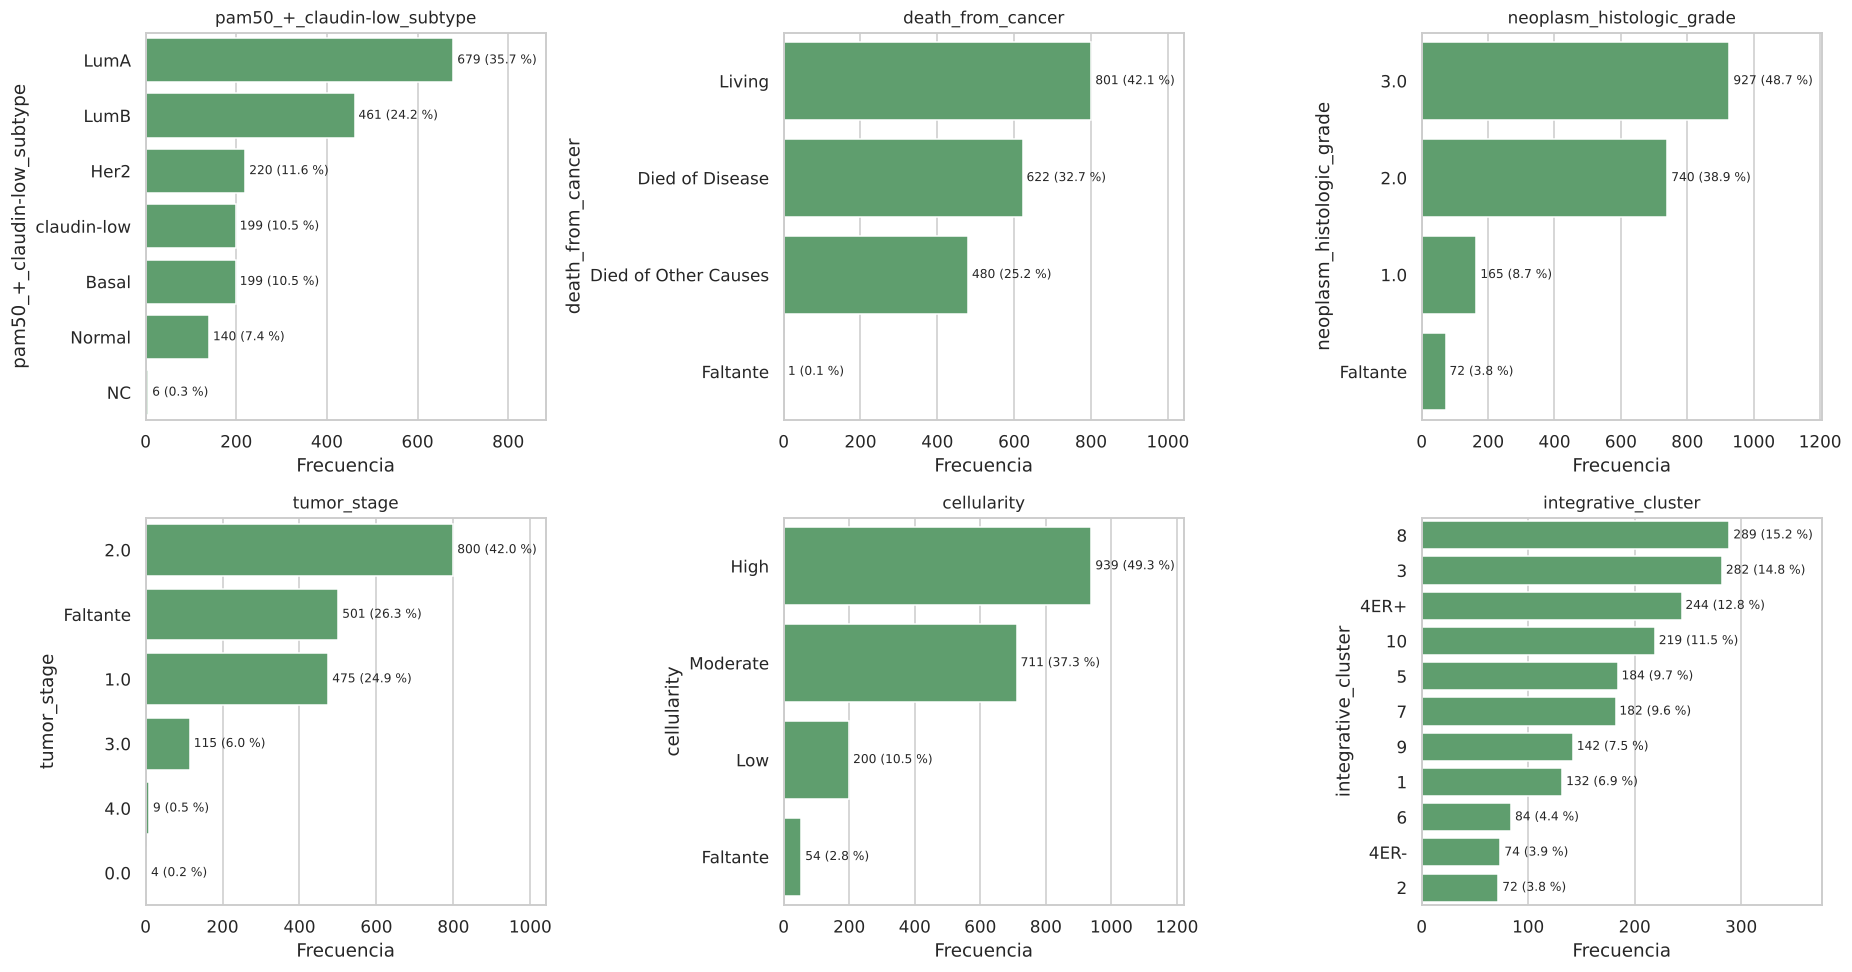

In [19]:
plot_vars = ["pam50_+_claudin-low_subtype", "death_from_cancer", "neoplasm_histologic_grade",
             "tumor_stage", "cellularity", "integrative_cluster"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.ravel(), plot_vars):
    vc = df[c].astype("string").fillna("Faltante").value_counts()
    sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color="#55A868")
    for i, v in enumerate(vc.values):
        ax.text(v, i, f" {v} ({100 * v / len(df):.1f} %)", va="center", fontsize=8)
    ax.set_title(c, fontsize=11)
    ax.set_xlabel("Frecuencia")
    ax.set_xlim(0, vc.max() * 1.3)
plt.tight_layout()
savefig("03_univariado_cualitativas")
plt.show()

### 7.3 Bloque de expresión génica y de mutaciones

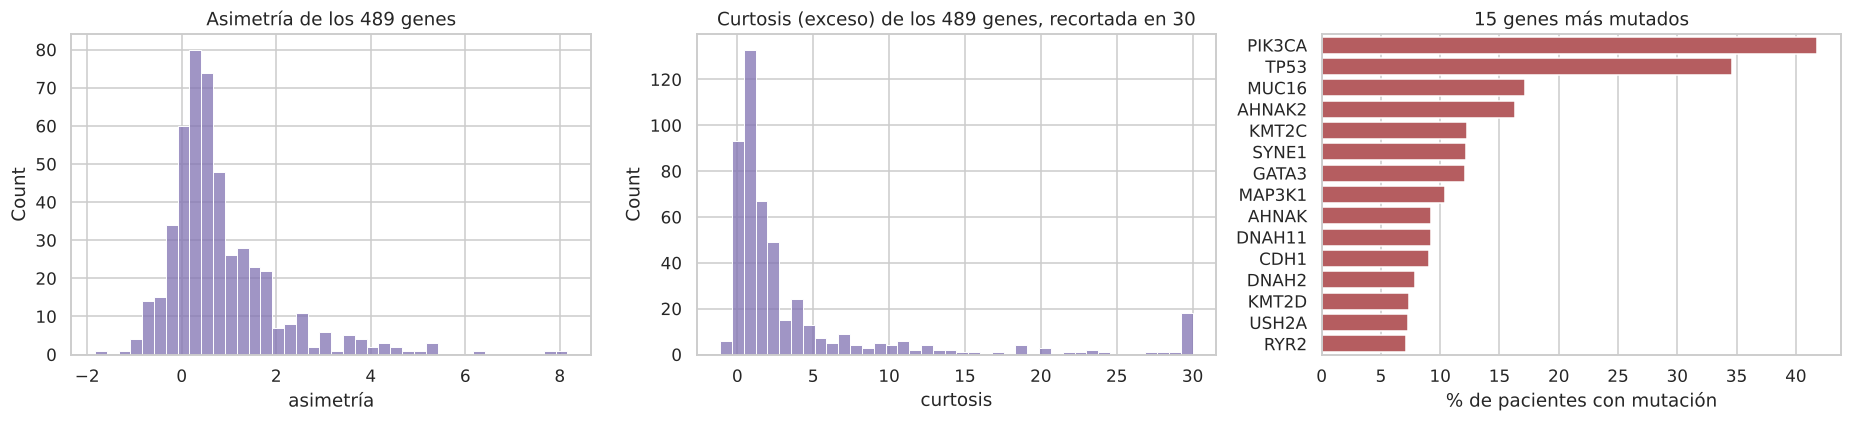

Genes con |asimetría| > 1: 148 de 489
Genes más asimétricos: magea8, lipi, tubb4a, ugt2b17, ddc, bche, inha, bmp5


In [20]:
g_skew = df[gene_cols].skew()
g_kurt = df[gene_cols].kurt()
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(g_skew, bins=40, ax=axes[0], color="#8172B2")
axes[0].set(title="Asimetría de los 489 genes", xlabel="asimetría")
sns.histplot(g_kurt.clip(upper=30), bins=40, ax=axes[1], color="#8172B2")
axes[1].set(title="Curtosis (exceso) de los 489 genes, recortada en 30", xlabel="curtosis")
top_mut = (100 * mut_rate).sort_values(ascending=False).head(15)
sns.barplot(x=top_mut.values, y=[m[:-4].upper() for m in top_mut.index], ax=axes[2], color="#C44E52")
axes[2].set(title="15 genes más mutados", xlabel="% de pacientes con mutación")
plt.tight_layout()
savefig("04_genes_mutaciones")
plt.show()
print(f"Genes con |asimetría| > 1: {(g_skew.abs() > 1).sum()} de {len(gene_cols)}")
print("Genes más asimétricos:", ", ".join(g_skew.abs().sort_values(ascending=False).head(8).index))

## 8. Análisis bivariado y multivariado
### 8.1 Matriz de correlación (Pearson y Spearman)
Se incluyen las variables cuantitativas y las ordinales codificadas numéricamente (grado y estadio). Spearman es la medida principal porque varias distribuciones son asimétricas y tienen atípicos.

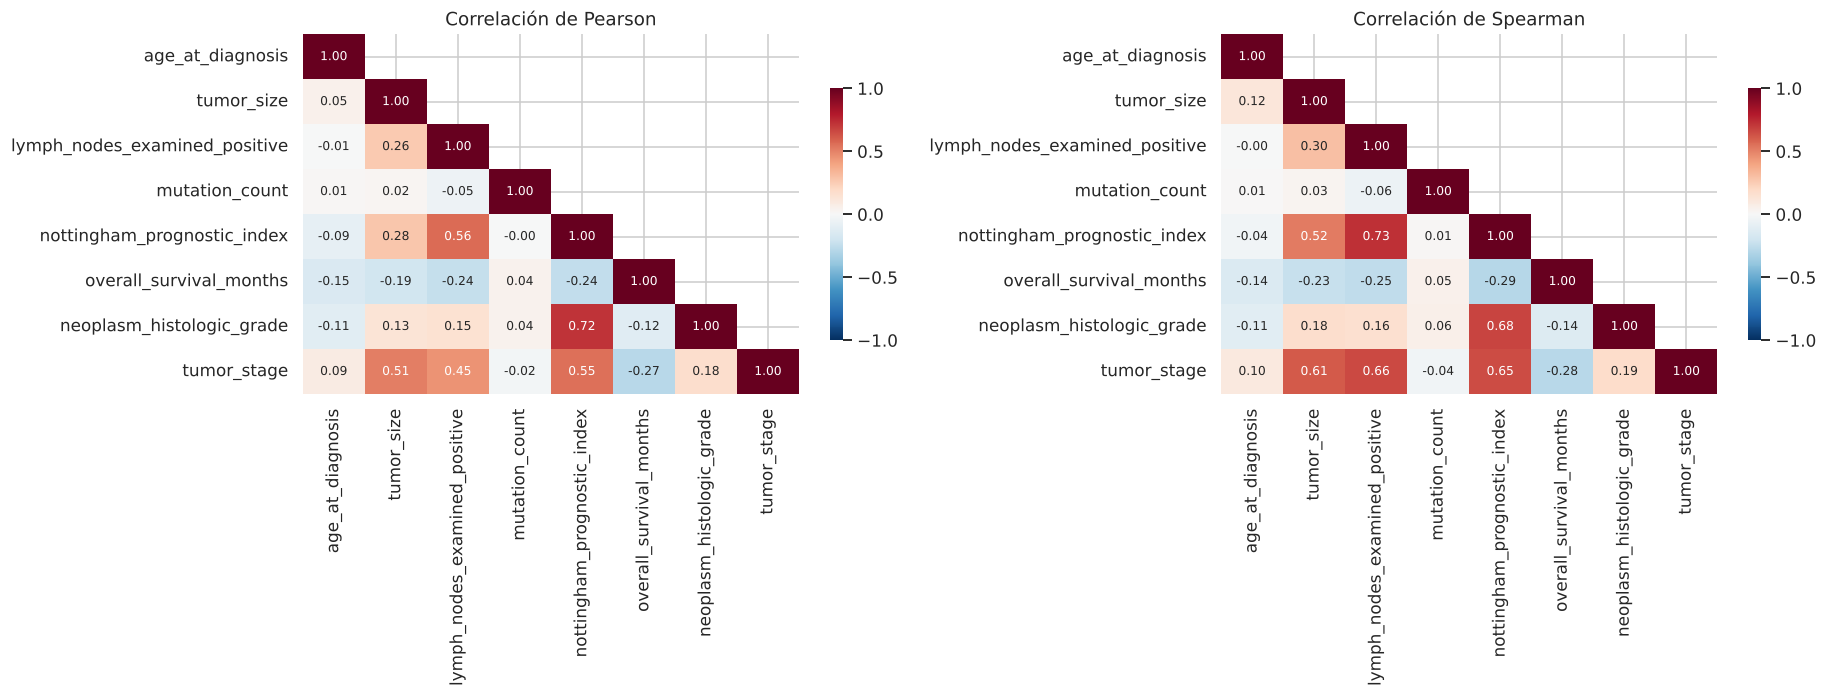

In [21]:
corr_vars = quant_clin + ["neoplasm_histologic_grade", "tumor_stage"]
pearson = df[corr_vars].corr(method="pearson")
spearman = df[corr_vars].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)
for ax, m, name in zip(axes, [pearson, spearman], ["Pearson", "Spearman"]):
    sns.heatmap(m, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax,
                cbar_kws={"shrink": .7}, annot_kws={"size": 8})
    ax.set_title(f"Correlación de {name}")
plt.tight_layout()
savefig("05_correlaciones")
plt.show()

In [22]:
# Significancia de las correlaciones de Spearman con el NPI
rows = []
for c in corr_vars:
    if c == "nottingham_prognostic_index":
        continue
    d = df[[c, "nottingham_prognostic_index"]].dropna()
    rho, p = stats.spearmanr(d[c], d["nottingham_prognostic_index"])
    rows.append({"variable": c, "rho_Spearman": rho, "p_valor": p, "n": len(d)})
pd.DataFrame(rows).set_index("variable").sort_values("rho_Spearman", key=abs, ascending=False)

,rho_Spearman,p_valor,n
variable,,,
lymph_nodes_examined_positive,0.734,0.000,1904
neoplasm_histologic_grade,0.675,0.000,1832
tumor_stage,0.652,0.000,1403
tumor_size,0.518,0.000,1884
overall_survival_months,-0.286,0.000,1904
age_at_diagnosis,-0.036,0.119,1904
mutation_count,0.008,0.722,1859


### 8.2 Diagramas de dispersión

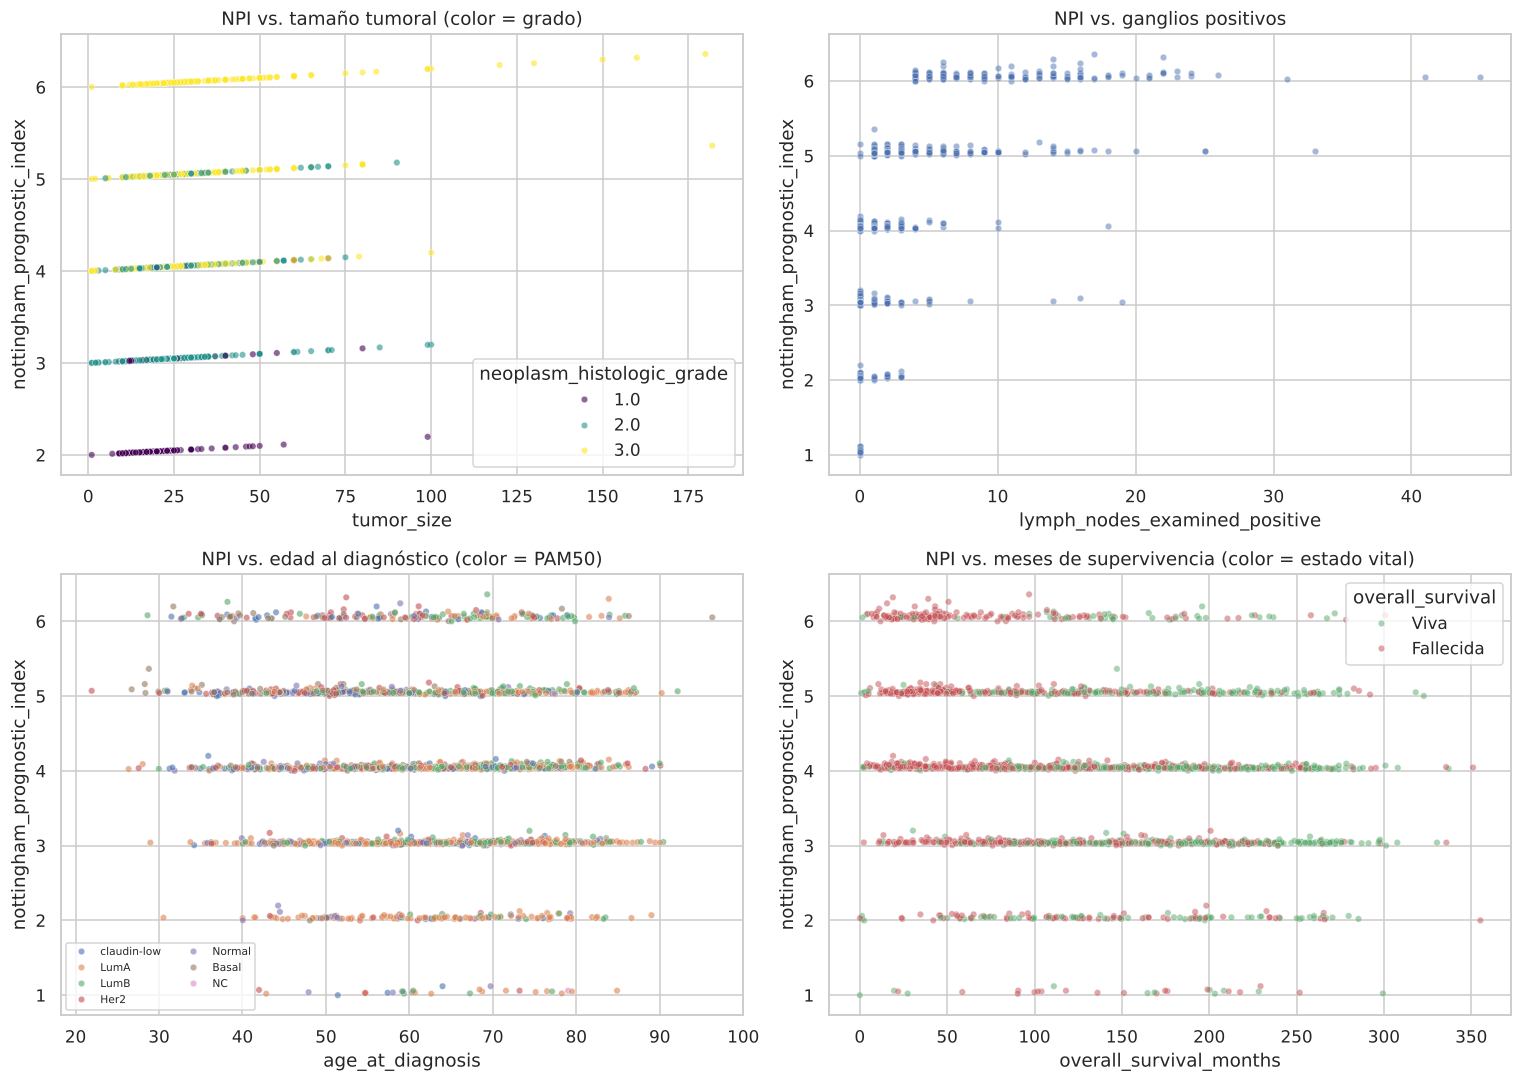

In [23]:
vital = df["overall_survival"].map({1: "Viva", 0: "Fallecida"})
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.scatterplot(data=df, x="tumor_size", y="nottingham_prognostic_index", hue="neoplasm_histologic_grade",
                palette="viridis", alpha=.6, s=18, ax=axes[0, 0])
axes[0, 0].set_title("NPI vs. tamaño tumoral (color = grado)")
sns.scatterplot(data=df, x="lymph_nodes_examined_positive", y="nottingham_prognostic_index",
                alpha=.5, s=18, ax=axes[0, 1], color="#4C72B0")
axes[0, 1].set_title("NPI vs. ganglios positivos")
sns.scatterplot(data=df, x="age_at_diagnosis", y="nottingham_prognostic_index", hue=df[config.TARGET_CLASSIFICATION],
                alpha=.6, s=18, ax=axes[1, 0])
axes[1, 0].set_title("NPI vs. edad al diagnóstico (color = PAM50)")
axes[1, 0].legend(fontsize=7, ncol=2)
sns.scatterplot(x=df["overall_survival_months"], y=df["nottingham_prognostic_index"], hue=vital,
                palette={"Viva": "#55A868", "Fallecida": "#C44E52"}, alpha=.5, s=18, ax=axes[1, 1])
axes[1, 1].set_title("NPI vs. meses de supervivencia (color = estado vital)")
plt.tight_layout()
savefig("06_dispersion")
plt.show()

### 8.3 Variable objetivo de regresión (NPI) según grupos cualitativos

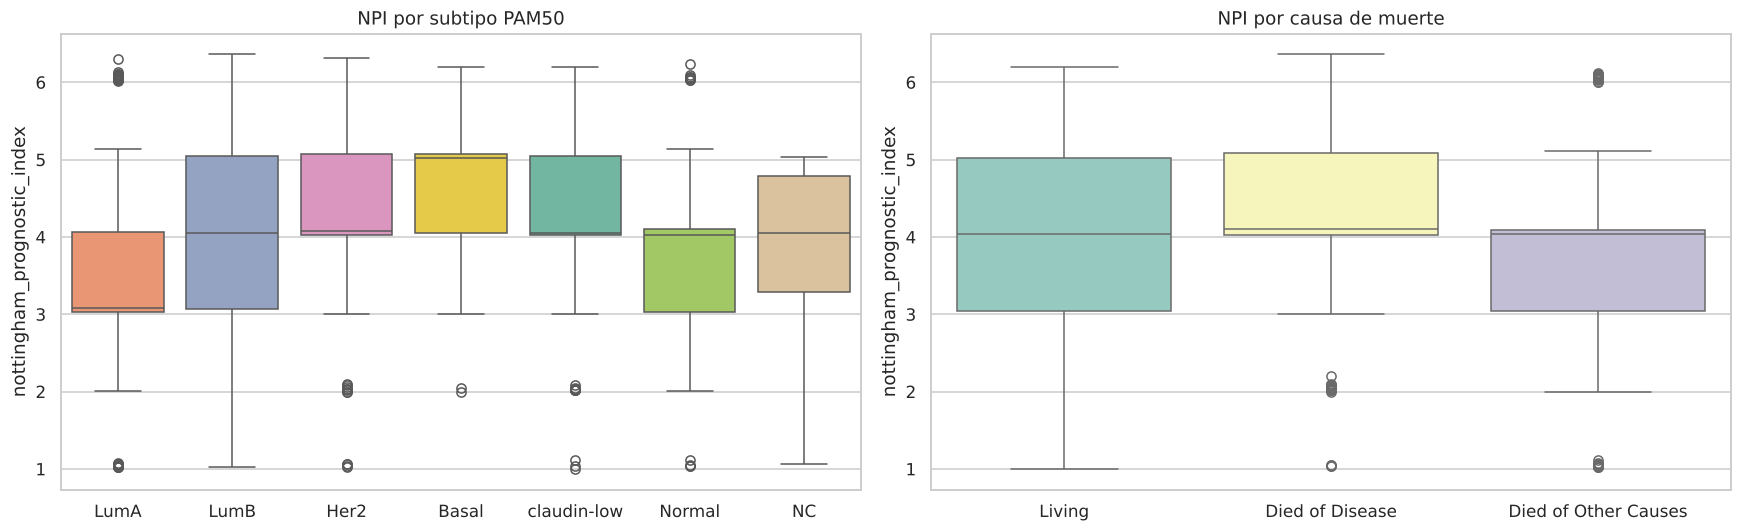

Kruskal-Wallis NPI ~ pam50_+_claudin-low_subtype: H = 222.5, p = 3.08e-45
Kruskal-Wallis NPI ~ death_from_cancer: H = 150.7, p = 1.87e-33
Kruskal-Wallis NPI ~ er_status: H = 150.3, p = 1.50e-34
Kruskal-Wallis NPI ~ her2_status: H = 56.4, p = 5.87e-14


In [24]:
order = ["LumA", "LumB", "Her2", "Basal", "claudin-low", "Normal", "NC"]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df, x=config.TARGET_CLASSIFICATION, y="nottingham_prognostic_index", order=order,
            ax=axes[0], palette="Set2", hue=config.TARGET_CLASSIFICATION, legend=False)
axes[0].set(title="NPI por subtipo PAM50", xlabel="")
sns.boxplot(data=df, x="death_from_cancer", y="nottingham_prognostic_index", ax=axes[1], palette="Set3",
            hue="death_from_cancer", legend=False)
axes[1].set(title="NPI por causa de muerte", xlabel="")
plt.tight_layout()
savefig("07_npi_por_grupo")
plt.show()

for g in [config.TARGET_CLASSIFICATION, "death_from_cancer", "er_status", "her2_status"]:
    groups = [s.dropna().values for _, s in df.groupby(g)["nottingham_prognostic_index"]]
    h, p = stats.kruskal(*groups)
    print(f"Kruskal-Wallis NPI ~ {g}: H = {h:.1f}, p = {p:.2e}")

### 8.4 Pruebas de independencia chi-cuadrado (χ²)
H₀: las dos variables cualitativas son independientes. Se reporta la V de Cramér como tamaño del efecto (≈ 0,1 pequeño, ≈ 0,3 mediano, ≥ 0,5 grande).

In [25]:
target_c = config.TARGET_CLASSIFICATION
pairs = [(target_c, v) for v in ["er_status", "pr_status", "her2_status", "neoplasm_histologic_grade",
                                 "cellularity", "inferred_menopausal_state", "death_from_cancer",
                                 "tumor_stage", "integrative_cluster", "primary_tumor_laterality"]]
pairs += [("death_from_cancer", "neoplasm_histologic_grade"), ("death_from_cancer", "chemotherapy"),
          ("er_status", "hormone_therapy"), ("er_status", "er_status_measured_by_ihc")]
chi_tbl = chi2_tests(df[df[target_c] != "NC"], pairs)
chi_tbl["¿dependientes? (α = 0,05)"] = np.where(chi_tbl["p_valor"] < 0.05, "Sí", "No")
chi_tbl.sort_values("V_Cramer", ascending=False).reset_index(drop=True)

,variable_1,variable_2,chi2,gl,p_valor,V_Cramer,%_celdas_esperado<5,"¿dependientes? (α = 0,05)"
0,er_status,er_status_measured_by_ihc,"1,260.675",1,0.000,0.823,0.000,Sí
1,pam50_+_claudin-low_subtype,er_status,"1,095.003",5,0.000,0.758,0.000,Sí
2,pam50_+_claudin-low_subtype,pr_status,506.271,5,0.000,0.514,0.000,Sí
3,pam50_+_claudin-low_subtype,her2_status,463.829,5,0.000,0.492,0.000,Sí
4,pam50_+_claudin-low_subtype,integrative_cluster,"2,089.049",50,0.000,0.464,0.000,Sí
5,er_status,hormone_therapy,267.601,1,0.000,0.376,0.000,Sí
6,pam50_+_claudin-low_subtype,neoplasm_histologic_grade,403.811,10,0.000,0.328,0.000,Sí
7,death_from_cancer,chemotherapy,111.816,2,0.000,0.241,0.000,Sí
8,pam50_+_claudin-low_subtype,cellularity,196.338,10,0.000,0.225,0.000,Sí
9,pam50_+_claudin-low_subtype,inferred_menopausal_state,91.718,5,0.000,0.214,0.000,Sí


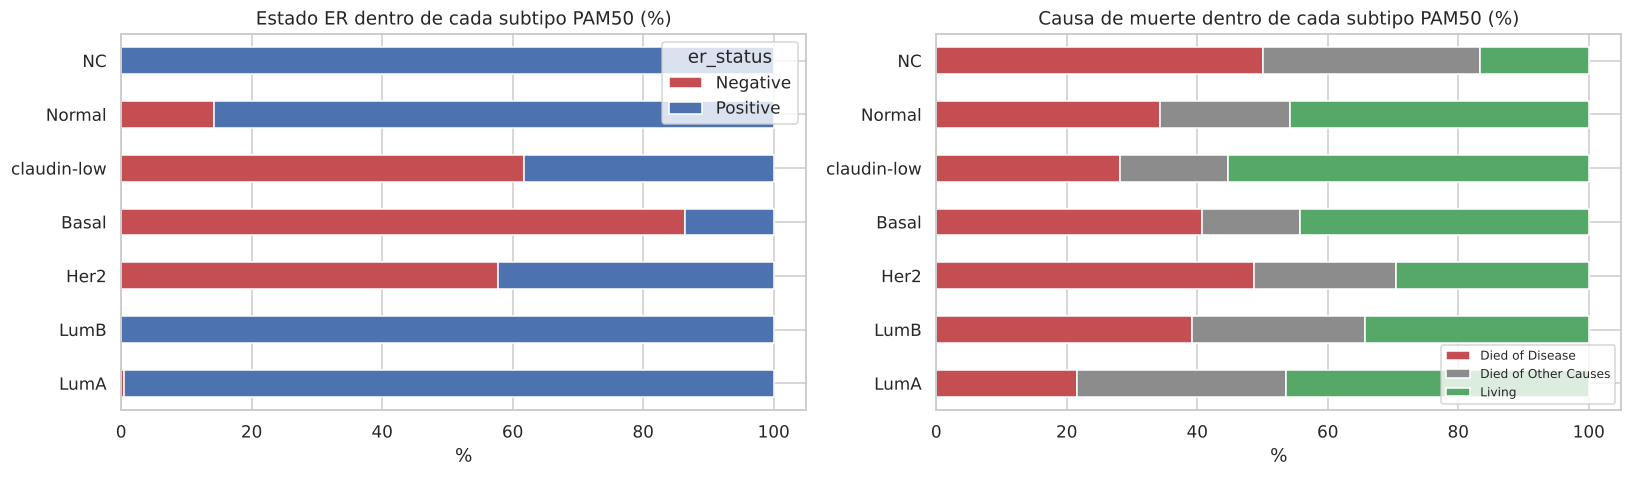

In [26]:
ct = pd.crosstab(df[target_c], df["er_status"], normalize="index") * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ct.loc[order].plot(kind="barh", stacked=True, ax=axes[0], color=["#C44E52", "#4C72B0"])
axes[0].set(title="Estado ER dentro de cada subtipo PAM50 (%)", xlabel="%", ylabel="")
ct2 = pd.crosstab(df[target_c], df["death_from_cancer"], normalize="index") * 100
ct2.loc[order].plot(kind="barh", stacked=True, ax=axes[1], color=["#C44E52", "#8C8C8C", "#55A868"])
axes[1].set(title="Causa de muerte dentro de cada subtipo PAM50 (%)", xlabel="%", ylabel="")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
savefig("08_pam50_cruces")
plt.show()

### 8.5 Expresión génica frente a las variables objetivo

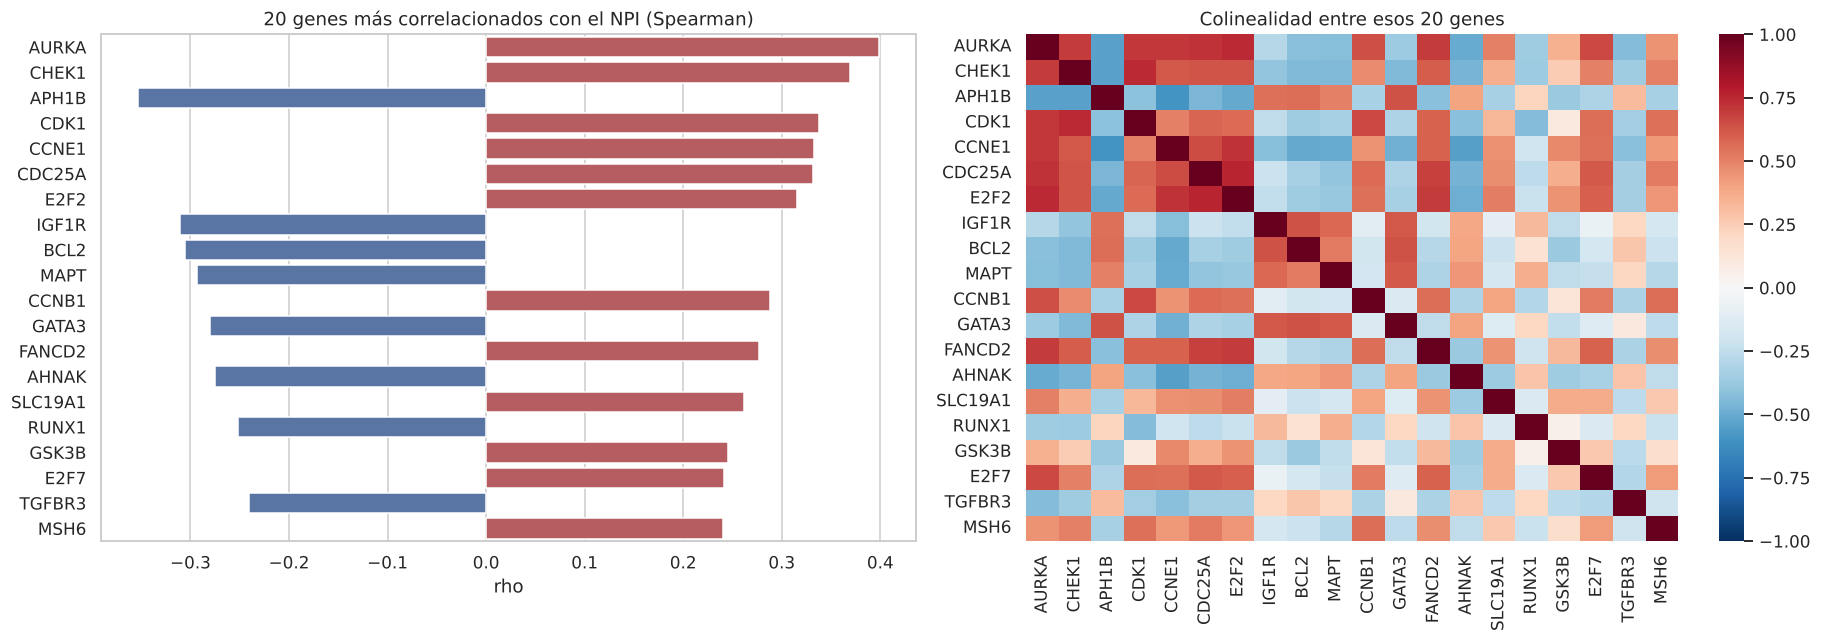

Genes con |rho| > 0,3 con el NPI: 9


In [27]:
# Genes con mayor correlación de Spearman (en valor absoluto) con el NPI
rho_npi = df[gene_cols].corrwith(df["nottingham_prognostic_index"], method="spearman")
top_genes = rho_npi.abs().sort_values(ascending=False).head(20).index
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.barplot(x=rho_npi[top_genes].values, y=[g.upper() for g in top_genes], ax=axes[0],
            palette=["#C44E52" if v > 0 else "#4C72B0" for v in rho_npi[top_genes]],
            hue=[g.upper() for g in top_genes], legend=False)
axes[0].set(title="20 genes más correlacionados con el NPI (Spearman)", xlabel="rho")
sns.heatmap(df[top_genes].corr(method="spearman"), cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1],
            xticklabels=[g.upper() for g in top_genes], yticklabels=[g.upper() for g in top_genes])
axes[1].set_title("Colinealidad entre esos 20 genes")
plt.tight_layout()
savefig("09_genes_npi")
plt.show()
print(f"Genes con |rho| > 0,3 con el NPI: {(rho_npi.abs() > 0.3).sum()}")

Genes con expresión significativamente distinta entre subtipos (Bonferroni, α = 1.0e-04): 406 de 489


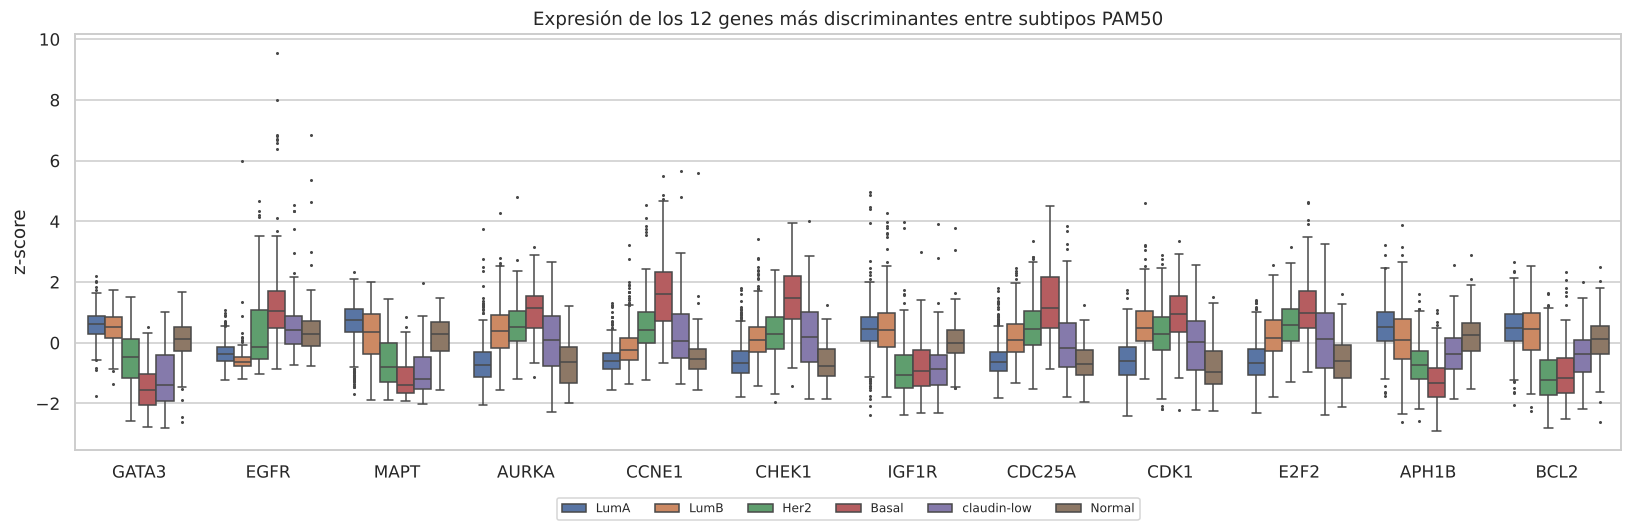

In [28]:
# Expresión diferencial por subtipo: Kruskal-Wallis por gen (con corrección de Bonferroni)
sub = df[df[target_c] != "NC"]
kw_p = {g: stats.kruskal(*[s.dropna() for _, s in sub.groupby(target_c)[g]])[1] for g in gene_cols}
kw_p = pd.Series(kw_p)
alpha_bonf = 0.05 / len(gene_cols)
print(f"Genes con expresión significativamente distinta entre subtipos (Bonferroni, α = {alpha_bonf:.1e}): "
      f"{(kw_p < alpha_bonf).sum()} de {len(gene_cols)}")
top_kw = kw_p.sort_values().head(12).index
fig, ax = plt.subplots(figsize=(15, 5))
long = sub.melt(id_vars=target_c, value_vars=list(top_kw), var_name="gen", value_name="z")
long["gen"] = long["gen"].str.upper()
sns.boxplot(data=long, x="gen", y="z", hue=target_c, hue_order=order[:-1], fliersize=1, ax=ax)
ax.set(title="Expresión de los 12 genes más discriminantes entre subtipos PAM50", xlabel="", ylabel="z-score")
ax.legend(ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
savefig("10_genes_pam50")
plt.show()

### 8.6 Vista multivariada: Análisis de Componentes Principales (PCA) de la expresión génica
Es una vista previa de la estructura que usará el clustering en la Fase 3. Para este diagnóstico, los pocos faltantes del bloque génico se imputan con la mediana; el tratamiento definitivo se justificará en la Fase 2.

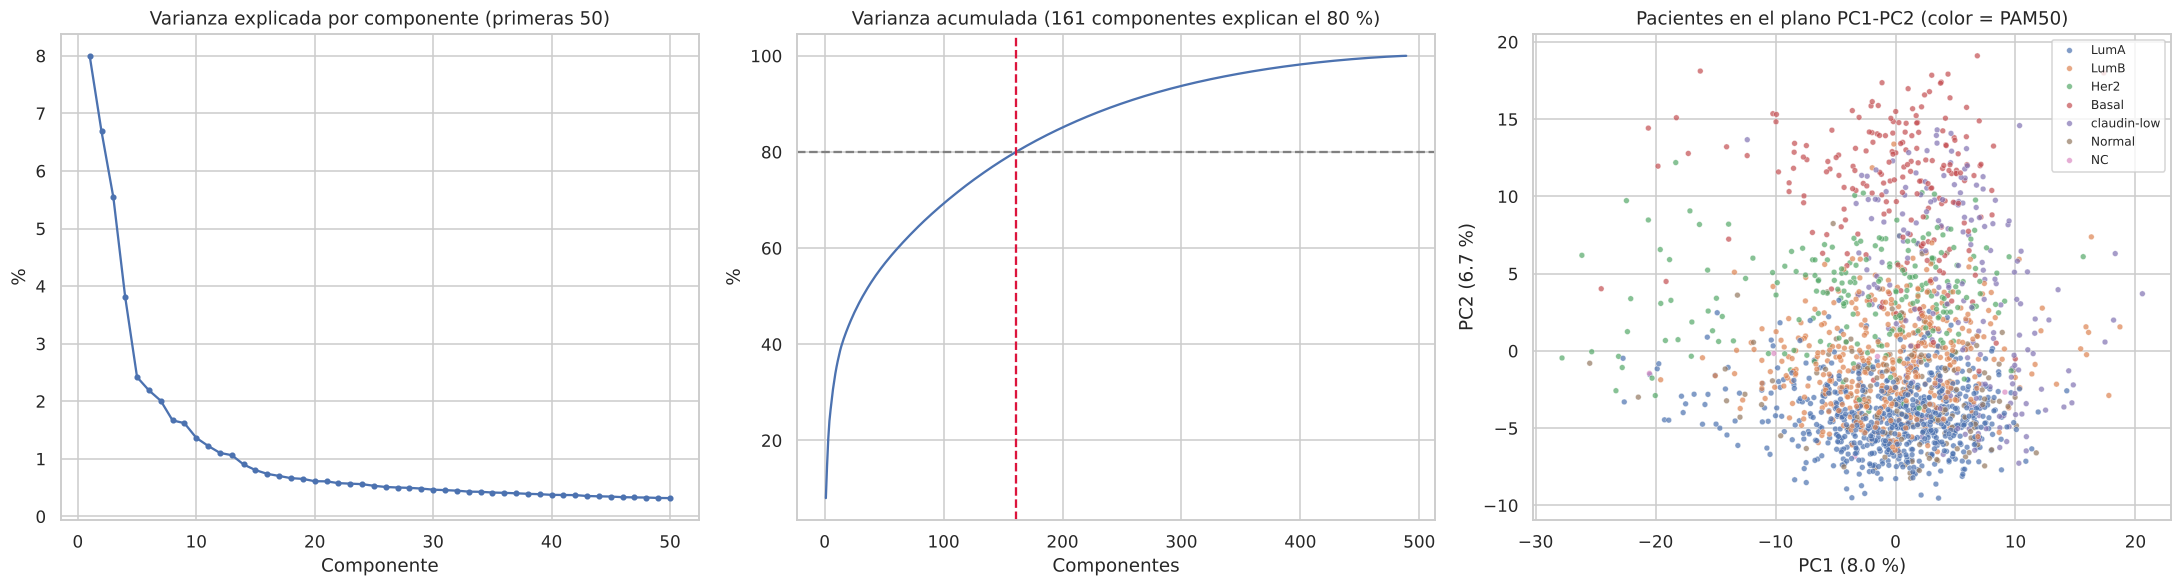

PC1: 8.00 % | PC2: 6.69 % | Componentes para el 80 %: 161 | para el 90 %: 249


In [29]:
X_genes = df[gene_cols].fillna(df[gene_cols].median())
X_scaled = StandardScaler().fit_transform(X_genes)
pca = PCA(random_state=config.RANDOM_STATE).fit(X_scaled)
cum = np.cumsum(pca.explained_variance_ratio_)
n80 = int(np.argmax(cum >= 0.80) + 1)
pcs = pca.transform(X_scaled)[:, :2]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].plot(range(1, 51), 100 * pca.explained_variance_ratio_[:50], marker="o", ms=3)
axes[0].set(title="Varianza explicada por componente (primeras 50)", xlabel="Componente", ylabel="%")
axes[1].plot(range(1, len(cum) + 1), 100 * cum)
axes[1].axhline(80, ls="--", c="gray")
axes[1].axvline(n80, ls="--", c="crimson")
axes[1].set(title=f"Varianza acumulada ({n80} componentes explican el 80 %)", xlabel="Componentes", ylabel="%")
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df[target_c], hue_order=order, s=14, alpha=.7, ax=axes[2])
axes[2].set(title="Pacientes en el plano PC1-PC2 (color = PAM50)",
            xlabel=f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f} %)",
            ylabel=f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f} %)")
axes[2].legend(fontsize=8)
plt.tight_layout()
savefig("11_pca_genes")
plt.show()
print(f"PC1: {100 * pca.explained_variance_ratio_[0]:.2f} % | PC2: {100 * pca.explained_variance_ratio_[1]:.2f} % | "
      f"Componentes para el 80 %: {n80} | para el 90 %: {int(np.argmax(cum >= 0.90) + 1)}")

## 9. Síntesis de hallazgos

**Estructura y calidad**
1. El conjunto tiene 1.904 pacientes y 693 variables, sin filas ni identificadores duplicados. Cumple todos los requisitos de la guía (más de 600 registros, mezcla de tipos y las tres variables objetivo).
2. Solo el 0,083 % de las celdas está vacío y todos los faltantes están en 13 variables clínicas; los bloques de genes y mutaciones están completos. Las variables más afectadas son `tumor_stage` (26,31 %) y `3-gene_classifier_subtype` (10,71 %). Solo el 57,4 % de las filas tiene todas las variables clínicas completas, así que eliminar filas con faltantes no es una opción.
3. Los faltantes de `tumor_stage` **no son completamente aleatorios (no MCAR)**: dependen de la cohorte (100 % en la cohorte 4 y 84,4 % en la 5; χ², p < 1e-265). Esto apunta a un mecanismo MAR asociado al centro de reclutamiento y debe considerarse al elegir la imputación.
4. Se encontraron incoherencias que se deben corregir: la categoría mal escrita `Positve` (1.445 registros), 118 discrepancias entre `er_status` y `er_status_measured_by_ihc`, 6 pacientes sin subtipo PAM50 (`NC`), un sarcoma en una cohorte de carcinomas, 17 tipos histológicos genéricos (`Breast`), 4 valores `UNDEF` en HER2, 4 tumores en estadio 0 y una supervivencia de 0 meses. `oncotree_code` duplica la información de `cancer_type_detailed`.

**Variable objetivo de regresión (NPI)**

5. En 1.812 de 1.815 registros completos, el NPI se reconstruye exactamente como grado + estadio ganglionar + 0,002 × tamaño (mm). Por tanto, **usar `tumor_size`, `lymph_nodes_examined_positive` o `neoplasm_histologic_grade` como predictores sería fuga de información**; tampoco conviene usar `tumor_stage`, que depende del tamaño y de los ganglios (ρ = 0,65 con el NPI). El coeficiente del tamaño es 10 veces menor que el de la fórmula clínica, una inconsistencia de escala de la fuente que se documentará.
6. El NPI es casi simétrico (asimetría −0,07, curtosis −0,34) y no tiene atípicos, pero se concentra cerca de valores enteros (moda en 4, con el 34,8 % de los casos). El modelo de regresión deberá evaluarse sabiendo que la variable se comporta como casi discreta.
7. Sin sus componentes, la relación del NPI con los genes es moderada: el coeficiente más alto es ρ = 0,40 (AURKA) y solo 9 genes superan |ρ| = 0,3. Los genes positivos son de proliferación y ciclo celular (AURKA, CHEK1, CDK1, CCNE1, CDC25A, E2F2) y forman un bloque muy colineal; los negativos son genes asociados a tumores luminales (BCL2, GATA3, IGF1R). La regularización de Lasso o ElasticNet es pertinente.

**Variable objetivo de clasificación (PAM50)**

8. Las clases están desbalanceadas: LumA tiene el 35,7 % de los casos y Normal-like el 7,4 %. Hará falta partición estratificada, ajuste de `class_weight` y F1 macro como métrica principal.
9. El subtipo está fuertemente asociado con el estado ER (V de Cramér = 0,76), PR (0,51), HER2 (0,49), el clúster integrativo (0,46) y el grado (0,33). Además, 406 de los 489 genes difieren significativamente entre subtipos (Kruskal-Wallis con Bonferroni), lo que anticipa un buen poder discriminante. El NPI también varía entre subtipos (H = 222,5; p < 1e-44); Basal y Her2 tienen los valores más altos.
10. La prueba χ² entre PAM50 y `tumor_stage` no es confiable (40 % de celdas con frecuencia esperada menor que 5). La lateralidad del tumor es independiente del subtipo (p = 0,35), como se esperaba.

**Distribuciones, atípicos y estructura multivariada**

11. Ninguna variable cuantitativa sigue una distribución normal (D'Agostino-Pearson, p < 0,05). `tumor_size`, `lymph_nodes_examined_positive` y `mutation_count` tienen asimetría positiva fuerte (curtosis entre 20 y 70) y concentran los atípicos (7,5 %, 11,0 % y 3,3 % por IQR). Son valores clínicamente plausibles, así que conviene transformarlos (logaritmo) o recortarlos por percentiles en lugar de eliminarlos.
12. El bloque génico tiene colas más pesadas que una normal (0,93 % de valores con |z| > 3, frente a 0,27 % esperado), y 148 genes tienen |asimetría| > 1.
13. La varianza de la expresión génica está muy repartida: PC1 explica el 8,0 %, PC2 el 6,7 % y se necesitan 161 componentes para llegar al 80 %. Aun así, el plano PC1-PC2 ya separa los tumores Basal (PC2 alto) de los Luminal A (PC2 bajo). Esto respalda reducir la dimensión con PCA antes del clustering y comparar los clústeres con PAM50.

## 10. Implicaciones para la Fase 2

| Aspecto | Decisión propuesta (a justificar en la Fase 2) |
|---|---|
| Correcciones | Unificar `Positve` como `Positive`; excluir los 6 casos `NC` de la clasificación y evaluar si se excluye el sarcoma; eliminar `oncotree_code` por redundante y `patient_id` como predictor. |
| Faltantes | Analizar el mecanismo por variable. `tumor_stage` es MAR respecto a la cohorte: imputarla con KNNImputer o IterativeImputer usando la cohorte como predictor, o descartarla. Las variables con menos del 6 % de faltantes se pueden imputar con la moda o la mediana dentro del pipeline. |
| Fuga de información | Excluir los componentes del NPI y `tumor_stage` de los predictores de regresión. Para clasificación, evaluar excluir `integrative_cluster` y `3-gene_classifier_subtype`, que se derivan de la misma expresión génica. Ajustar imputadores y escaladores solo con el conjunto de entrenamiento. |
| Atípicos | Aplicar `log1p` a `tumor_size`, `lymph_nodes_examined_positive` y `mutation_count`, o winsorizar en los percentiles 1 y 99. |
| Variables derivadas | (1) Puntaje de proliferación: promedio de los z-scores de AURKA, CHEK1, CDK1, CCNE1, CDC25A y E2F2. (2) Carga mutacional en genes conductores: número de mutaciones en PIK3CA, TP53, GATA3, MAP3K1, CDH1 y KMT2C. (3) Indicador triple negativo (ER−, PR− y HER2−). |
| Codificación | One-Hot para nominales y Ordinal para `cellularity` (Low < Moderate < High) y el grado histológico. |
| Partición | 70 % entrenamiento, 15 % validación y 15 % prueba, estratificando por PAM50 y con semilla fija (42). |
| Modelos base | Regresión lineal simple y `DummyRegressor` para el NPI; `DummyClassifier` y regresión logística básica para PAM50. |